Final Model Evaluation and Multi-Level Results Analysis

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


Import libraries

In [ ]:
import os
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

SEED = 42
HORIZON = 28

print("Step 13 libraries loaded successfully.")

Step 13 libraries loaded successfully.


Define project paths

In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/GC210_Retail_Forecasting"

PROCESSED_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "processed"
)

SUPERVISED_DIR = os.path.join(
    PROCESSED_DIR,
    "supervised"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results"
)

METRICS_DIR = os.path.join(
    RESULTS_DIR,
    "metrics"
)

PREDICTIONS_DIR = os.path.join(
    RESULTS_DIR,
    "predictions"
)

FIGURES_DIR = os.path.join(
    RESULTS_DIR,
    "figures"
)

FINAL_RESULTS_DIR = os.path.join(
    RESULTS_DIR,
    "final_analysis"
)

os.makedirs(
    FINAL_RESULTS_DIR,
    exist_ok=True
)

print(
    "Final analysis directory:",
    FINAL_RESULTS_DIR
)

Final analysis directory: /content/drive/MyDrive/GC210_Retail_Forecasting/results/final_analysis


Load final model comparison

In [ ]:
COMPLETE_COMPARISON_PATH = os.path.join(
    METRICS_DIR,
    "complete_model_comparison.csv"
)

if not os.path.exists(
    COMPLETE_COMPARISON_PATH
):
    raise FileNotFoundError(
        "complete_model_comparison.csv missing. "
        "Run Step 12 first."
    )

overall_metrics = pd.read_csv(
    COMPLETE_COMPARISON_PATH
)

print(
    "Models available:",
    len(overall_metrics)
)

display(
    overall_metrics.round(4)
)

Models available: 14


,Model,MAE,RMSE,WAPE,sMAPE
0,Seasonal Naive,1.2555,2.8744,105.8198,86.5290
1,MLP,0.9003,1.8435,75.8873,151.5955
2,LightGBM,0.8469,1.8054,71.3810,102.4982
3,AE + MLP,1.0662,1.8089,89.8639,136.1644
4,DAE + MLP,1.1905,2.8978,100.3419,128.1398
5,SAE + MLP,0.9248,1.9480,77.9485,125.4724
6,LSTM,0.8332,1.7894,70.2268,127.8854
7,Transformer,0.8384,1.7694,70.6655,133.3020
8,AE + LSTM,0.8476,1.7896,71.4440,114.0228
9,DAE + LSTM,0.8488,1.7909,71.5465,125.3335


Clean and verify overall metrics

In [ ]:
METRIC_COLUMNS = [
    "MAE",
    "RMSE",
    "WAPE",
    "sMAPE"
]

for col in METRIC_COLUMNS:

    overall_metrics[col] = pd.to_numeric(
        overall_metrics[col],
        errors="coerce"
    )

print(
    overall_metrics[
        METRIC_COLUMNS
    ]
    .isna()
    .sum()
)

display(
    overall_metrics.round(4)
)

MAE      0
RMSE     0
WAPE     0
sMAPE    0
dtype: int64


,Model,MAE,RMSE,WAPE,sMAPE
0,Seasonal Naive,1.2555,2.8744,105.8198,86.5290
1,MLP,0.9003,1.8435,75.8873,151.5955
2,LightGBM,0.8469,1.8054,71.3810,102.4982
3,AE + MLP,1.0662,1.8089,89.8639,136.1644
4,DAE + MLP,1.1905,2.8978,100.3419,128.1398
5,SAE + MLP,0.9248,1.9480,77.9485,125.4724
6,LSTM,0.8332,1.7894,70.2268,127.8854
7,Transformer,0.8384,1.7694,70.6655,133.3020
8,AE + LSTM,0.8476,1.7896,71.4440,114.0228
9,DAE + LSTM,0.8488,1.7909,71.5465,125.3335


Create descriptive ranking tables

In [ ]:
ranked_metrics = (
    overall_metrics
    .sort_values(
        "MAE",
        ascending=True
    )
    .reset_index(drop=True)
)

ranked_metrics[
    "MAE_Rank"
] = np.arange(
    1,
    len(ranked_metrics) + 1
)

display(
    ranked_metrics[
        [
            "MAE_Rank",
            "Model",
            "MAE",
            "RMSE",
            "WAPE",
            "sMAPE"
        ]
    ].round(4)
)

,MAE_Rank,Model,MAE,RMSE,WAPE,sMAPE
0,1,LSTM,0.8332,1.7894,70.2268,127.8854
1,2,DAE + Transformer,0.8372,1.7858,70.5612,119.5099
2,3,Transformer,0.8384,1.7694,70.6655,133.3020
3,4,SAE + Transformer,0.8449,1.7772,71.2111,115.7377
4,5,LightGBM,0.8469,1.8054,71.3810,102.4982
5,6,AE + LSTM,0.8476,1.7896,71.4440,114.0228
6,7,DAE + LSTM,0.8488,1.7909,71.5465,125.3335
7,8,AE + Transformer,0.8590,1.8795,72.4039,126.6875
8,9,SAE + LSTM,0.8819,1.8245,74.3301,132.4461
9,10,MLP,0.9003,1.8435,75.8873,151.5955


In [ ]:
OVERALL_RESULTS_PATH = os.path.join(
    FINAL_RESULTS_DIR,
    "overall_model_results.csv"
)

ranked_metrics.to_csv(
    OVERALL_RESULTS_PATH,
    index=False
)

print(
    "Saved:",
    OVERALL_RESULTS_PATH
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/final_analysis/overall_model_results.csv


Plot RMSE comparison

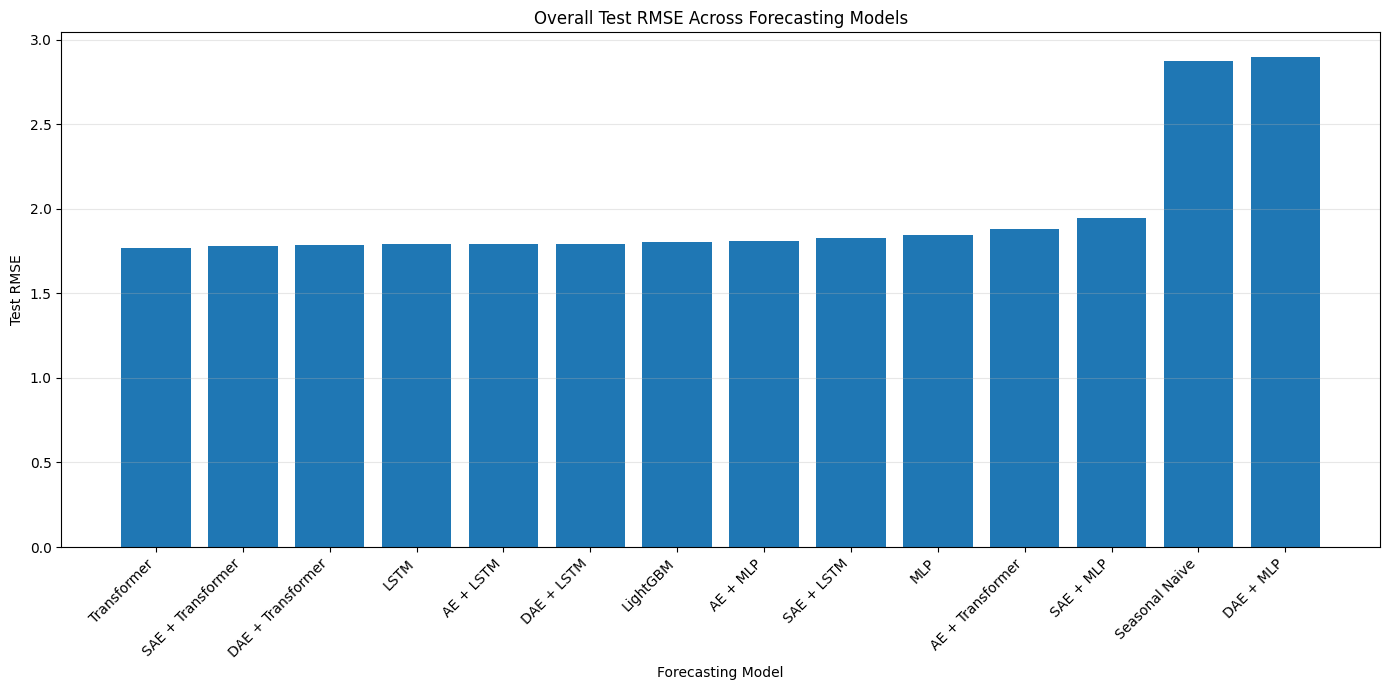

In [ ]:
plot_df = (
    overall_metrics
    .sort_values(
        "RMSE",
        ascending=True
    )
)

plt.figure(
    figsize=(14, 7)
)

plt.bar(
    plot_df["Model"],
    plot_df["RMSE"]
)

plt.xlabel(
    "Forecasting Model"
)

plt.ylabel(
    "Test RMSE"
)

plt.title(
    "Overall Test RMSE Across Forecasting Models"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

RMSE_FIG = os.path.join(
    FIGURES_DIR,
    "final_overall_rmse_comparison.png"
)

plt.savefig(
    RMSE_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Plot WAPE comparison

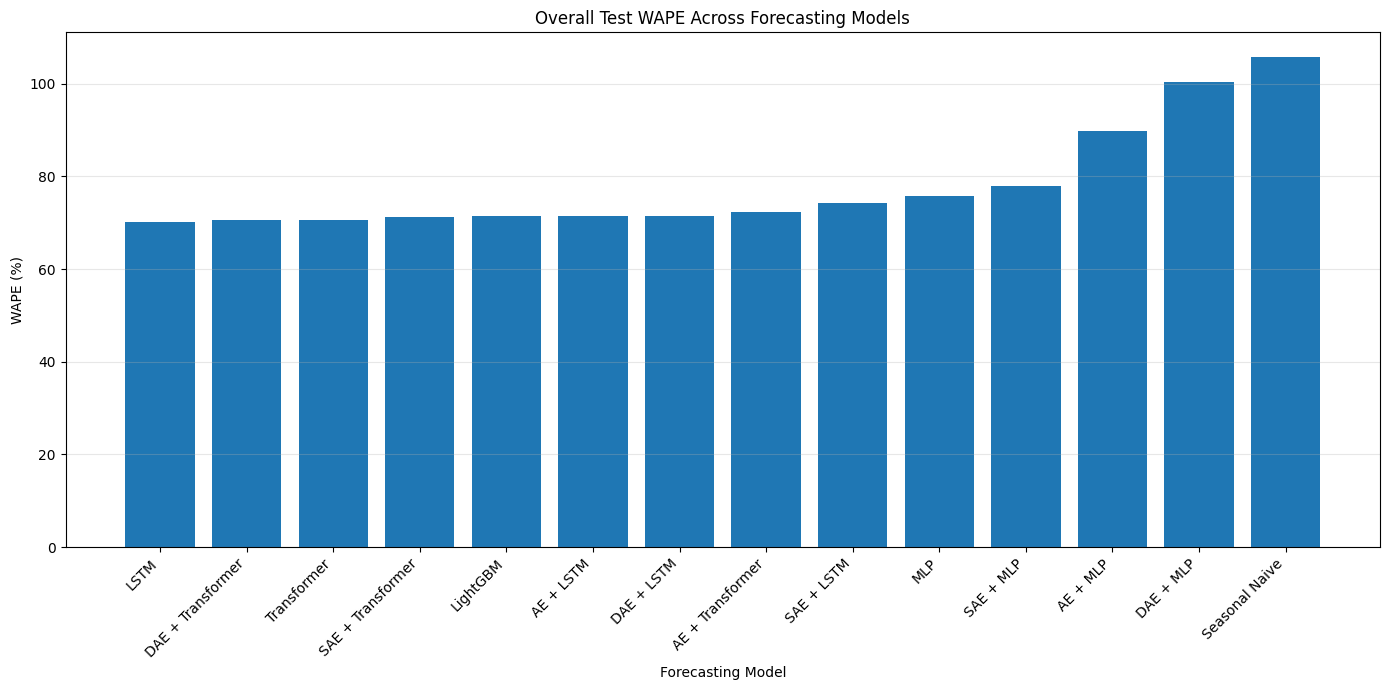

In [ ]:
plot_df = (
    overall_metrics
    .sort_values(
        "WAPE",
        ascending=True
    )
)

plt.figure(
    figsize=(14, 7)
)

plt.bar(
    plot_df["Model"],
    plot_df["WAPE"]
)

plt.xlabel(
    "Forecasting Model"
)

plt.ylabel(
    "WAPE (%)"
)

plt.title(
    "Overall Test WAPE Across Forecasting Models"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

WAPE_FIG = os.path.join(
    FIGURES_DIR,
    "final_overall_wape_comparison.png"
)

plt.savefig(
    WAPE_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Plot sMAPE comparison

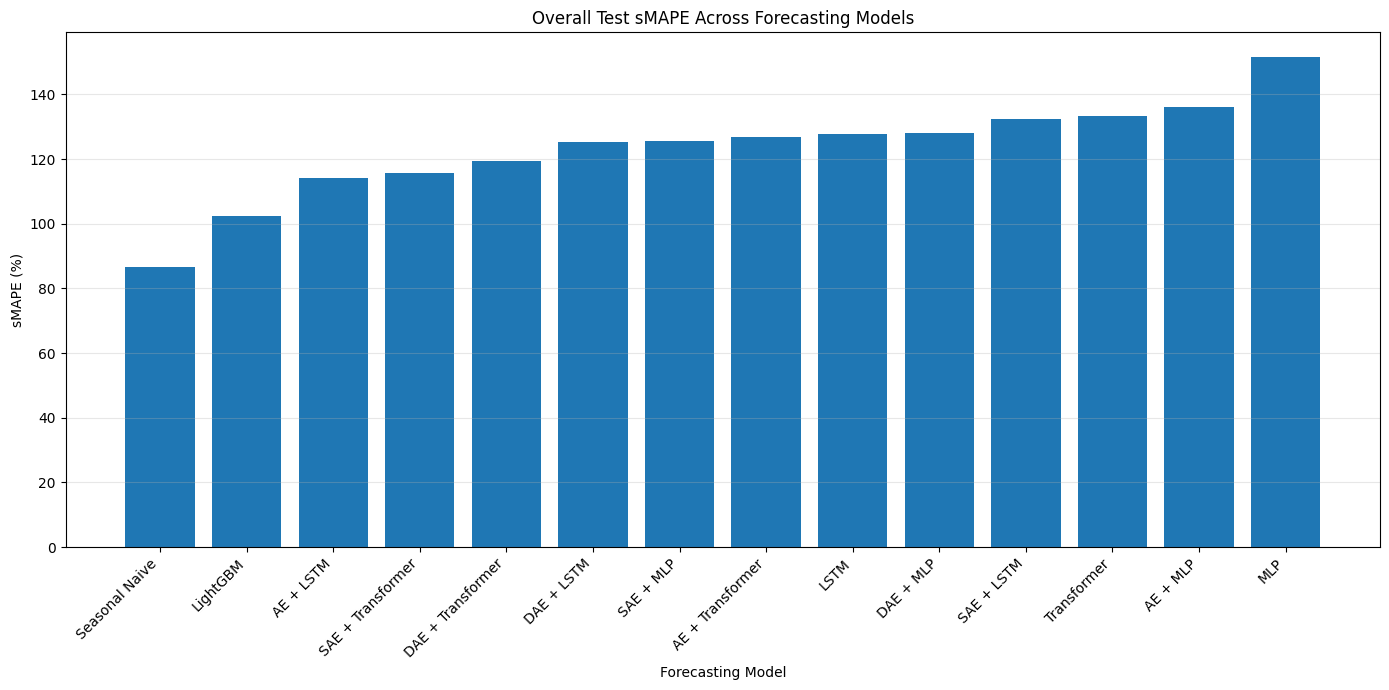

In [ ]:
plot_df = (
    overall_metrics
    .sort_values(
        "sMAPE",
        ascending=True
    )
)

plt.figure(
    figsize=(14, 7)
)

plt.bar(
    plot_df["Model"],
    plot_df["sMAPE"]
)

plt.xlabel(
    "Forecasting Model"
)

plt.ylabel(
    "sMAPE (%)"
)

plt.title(
    "Overall Test sMAPE Across Forecasting Models"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

SMAPE_FIG = os.path.join(
    FIGURES_DIR,
    "final_overall_smape_comparison.png"
)

plt.savefig(
    SMAPE_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Load Step 12 predictions

In [ ]:
STEP12_PREDICTIONS_PATH = os.path.join(
    PREDICTIONS_DIR,
    "latent_temporal_test_predictions.csv"
)

if not os.path.exists(
    STEP12_PREDICTIONS_PATH
):
    raise FileNotFoundError(
        "Step 12 prediction file missing."
    )

latent_predictions = pd.read_csv(
    STEP12_PREDICTIONS_PATH
)

latent_predictions[
    "origin_date"
] = pd.to_datetime(
    latent_predictions[
        "origin_date"
    ]
)

print(
    "Prediction rows:",
    latent_predictions.shape
)

print(
    "\nModels:"
)

print(
    latent_predictions[
        "Model"
    ].unique()
)

display(
    latent_predictions.head()
)

Prediction rows: (50400, 6)

Models:
['AE + LSTM' 'DAE + LSTM' 'SAE + LSTM' 'AE + Transformer'
 'DAE + Transformer' 'SAE + Transformer']


,Model,series_key,origin_date,forecast_day,actual,prediction
0,AE + LSTM,FOODS_1_005_TX_3,2016-04-24,1,1.0,1.019983
1,AE + LSTM,FOODS_1_005_TX_3,2016-04-24,2,0.0,1.097446
2,AE + LSTM,FOODS_1_005_TX_3,2016-04-24,3,4.0,1.183575
3,AE + LSTM,FOODS_1_005_TX_3,2016-04-24,4,1.0,1.436088
4,AE + LSTM,FOODS_1_005_TX_3,2016-04-24,5,1.0,1.434053


Load test metadata

In [ ]:
TEST_SUPERVISED_PATH = os.path.join(
    SUPERVISED_DIR,
    "test_supervised_28d.parquet"
)

test_metadata = pd.read_parquet(
    TEST_SUPERVISED_PATH
)

test_metadata["date"] = pd.to_datetime(
    test_metadata["date"]
)

metadata_columns = [
    "series_key",
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id"
]

metadata_columns = [
    col
    for col in metadata_columns
    if col in test_metadata.columns
]

series_metadata = (
    test_metadata[
        metadata_columns
    ]
    .drop_duplicates(
        subset=["series_key"]
    )
)

print(
    "Series metadata:",
    series_metadata.shape
)

display(
    series_metadata.head()
)

Series metadata: (300, 1)


,series_key
0,FOODS_1_005_TX_3
1,FOODS_1_049_TX_2
2,FOODS_1_079_CA_2
3,FOODS_1_079_CA_4
4,FOODS_1_083_WI_2


Merge metadata with predictions

In [ ]:
analysis_predictions = (
    latent_predictions
    .merge(
        series_metadata,
        on="series_key",
        how="left"
    )
)

# Dynamically extract missing IDs from series_key if they don't exist
if "cat_id" not in analysis_predictions.columns:
    analysis_predictions["cat_id"] = analysis_predictions["series_key"].apply(lambda x: x.split("_")[0])

if "dept_id" not in analysis_predictions.columns:
    analysis_predictions["dept_id"] = analysis_predictions["series_key"].apply(lambda x: "_".join(x.split("_")[:2]))

if "store_id" not in analysis_predictions.columns:
    analysis_predictions["store_id"] = analysis_predictions["series_key"].apply(lambda x: "_".join(x.split("_")[-2:]))

if "state_id" not in analysis_predictions.columns:
    analysis_predictions["state_id"] = analysis_predictions["series_key"].apply(lambda x: x.split("_")[-2])

print(
    "Analysis dataset:",
    analysis_predictions.shape
)

print(
    "\nMissing store IDs:",
    analysis_predictions[
        "store_id"
    ]
    .isna()
    .sum()
)

print(
    "Missing categories:",
    analysis_predictions[
        "cat_id"
    ]
    .isna()
    .sum()
)

display(
    analysis_predictions.head()
)

Analysis dataset: (50400, 10)

Missing store IDs: 0
Missing categories: 0


,Model,series_key,origin_date,forecast_day,actual,prediction,cat_id,dept_id,store_id,state_id
0,AE + LSTM,FOODS_1_005_TX_3,2016-04-24,1,1.0,1.019983,FOODS,FOODS_1,TX_3,TX
1,AE + LSTM,FOODS_1_005_TX_3,2016-04-24,2,0.0,1.097446,FOODS,FOODS_1,TX_3,TX
2,AE + LSTM,FOODS_1_005_TX_3,2016-04-24,3,4.0,1.183575,FOODS,FOODS_1,TX_3,TX
3,AE + LSTM,FOODS_1_005_TX_3,2016-04-24,4,1.0,1.436088,FOODS,FOODS_1,TX_3,TX
4,AE + LSTM,FOODS_1_005_TX_3,2016-04-24,5,1.0,1.434053,FOODS,FOODS_1,TX_3,TX


Add absolute and squared errors

In [ ]:
analysis_predictions[
    "absolute_error"
] = np.abs(
    analysis_predictions[
        "actual"
    ]
    -
    analysis_predictions[
        "prediction"
    ]
)

analysis_predictions[
    "squared_error"
] = (
    analysis_predictions[
        "actual"
    ]
    -
    analysis_predictions[
        "prediction"
    ]
) ** 2

print(
    "Error columns created."
)

Error columns created.


Define grouped evaluation function

In [ ]:
def grouped_metrics(
    dataframe,
    group_columns
):

    results = []

    for keys, group in dataframe.groupby(
        group_columns
    ):

        if not isinstance(
            keys,
            tuple
        ):
            keys = (keys,)

        y_true = (
            group["actual"]
            .to_numpy(
                dtype=np.float64
            )
        )

        y_pred = (
            group["prediction"]
            .to_numpy(
                dtype=np.float64
            )
        )

        mae = np.mean(
            np.abs(
                y_true - y_pred
            )
        )

        rmse = np.sqrt(
            np.mean(
                (
                    y_true - y_pred
                ) ** 2
            )
        )

        denominator = np.sum(
            np.abs(y_true)
        )

        wape = (
            np.sum(
                np.abs(
                    y_true - y_pred
                )
            )
            /
            denominator
            * 100
        ) if denominator > 0 else np.nan

        smape_denominator = (
            np.abs(y_true)
            +
            np.abs(y_pred)
        )

        smape_values = np.divide(
            2 * np.abs(
                y_true - y_pred
            ),
            smape_denominator,
            out=np.zeros_like(
                y_true,
                dtype=np.float64
            ),
            where=(
                smape_denominator != 0
            )
        )

        smape = (
            np.mean(
                smape_values
            ) * 100
        )

        result = {
            col: value
            for col, value
            in zip(
                group_columns,
                keys
            )
        }

        result.update({
            "MAE":
                mae,

            "RMSE":
                rmse,

            "WAPE":
                wape,

            "sMAPE":
                smape,

            "Observations":
                len(group)
        })

        results.append(
            result
        )

    return pd.DataFrame(
        results
    )

Store-level evaluation

In [ ]:
store_results = grouped_metrics(
    analysis_predictions,
    [
        "Model",
        "store_id"
    ]
)

store_results = (
    store_results
    .sort_values([
        "Model",
        "store_id"
    ])
    .reset_index(drop=True)
)

display(
    store_results.round(4)
)

,Model,store_id,MAE,RMSE,WAPE,sMAPE,Observations
0,AE + LSTM,CA_1,0.9069,1.5154,76.3729,117.4814,560
1,AE + LSTM,CA_2,1.6537,3.7181,54.1177,97.8741,700
2,AE + LSTM,CA_3,1.0684,1.8598,63.7378,110.5704,840
3,AE + LSTM,CA_4,0.7092,1.5304,89.7244,117.6411,1064
4,AE + LSTM,TX_1,0.5660,1.0868,88.2364,118.1374,1400
5,AE + LSTM,TX_2,0.5364,0.9940,78.4150,117.0122,728
6,AE + LSTM,TX_3,1.0094,2.0919,58.9704,107.2570,784
7,AE + LSTM,WI_1,0.8381,1.5484,80.5763,117.7444,672
8,AE + LSTM,WI_2,0.8155,1.3911,81.9983,112.7084,924
9,AE + LSTM,WI_3,0.7027,1.3562,91.8486,120.2022,728


In [ ]:
STORE_RESULTS_PATH = os.path.join(
    FINAL_RESULTS_DIR,
    "store_level_results.csv"
)

store_results.to_csv(
    STORE_RESULTS_PATH,
    index=False
)

print(
    "Saved:",
    STORE_RESULTS_PATH
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/final_analysis/store_level_results.csv


Store-level MAE pivot table

In [ ]:
store_mae_pivot = (
    store_results
    .pivot(
        index="store_id",
        columns="Model",
        values="MAE"
    )
)

display(
    store_mae_pivot.round(4)
)

Model,AE + LSTM,AE + Transformer,DAE + LSTM,DAE + Transformer,SAE + LSTM,SAE + Transformer
store_id,,,,,,
CA_1,0.9069,0.9026,0.9449,0.8775,0.9057,0.8525
CA_2,1.6537,1.7341,1.6345,1.6266,1.7142,1.6407
CA_3,1.0684,1.0993,1.0770,1.0455,1.0918,1.0543
CA_4,0.7092,0.6875,0.7223,0.7024,0.7308,0.6662
TX_1,0.5660,0.5618,0.5573,0.5518,0.6162,0.5828
TX_2,0.5364,0.5357,0.5324,0.5260,0.6143,0.5895
TX_3,1.0094,1.0722,1.0195,1.0398,1.0600,1.0265
WI_1,0.8381,0.8518,0.8513,0.8639,0.8257,0.8122
WI_2,0.8155,0.8237,0.8112,0.8050,0.8309,0.8137


Plot store-level performance

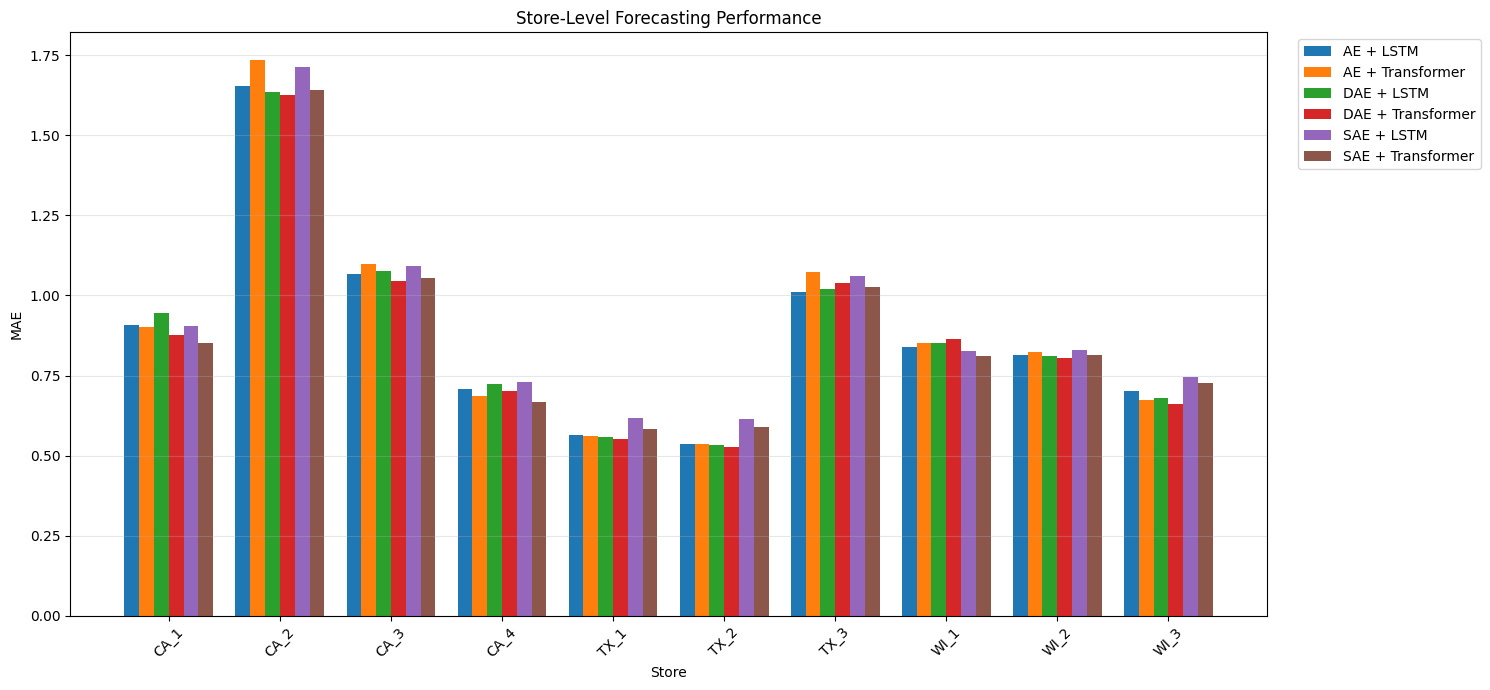

In [ ]:
plt.figure(
    figsize=(15, 7)
)

x = np.arange(
    len(
        store_mae_pivot.index
    )
)

models = list(
    store_mae_pivot.columns
)

width = (
    0.8 /
    max(
        len(models),
        1
    )
)

for i, model in enumerate(
    models
):

    plt.bar(
        x + i * width,
        store_mae_pivot[
            model
        ].values,
        width=width,
        label=model
    )

plt.xlabel(
    "Store"
)

plt.ylabel(
    "MAE"
)

plt.title(
    "Store-Level Forecasting Performance"
)

plt.xticks(
    x + width * (
        len(models) - 1
    ) / 2,
    store_mae_pivot.index,
    rotation=45
)

plt.legend(
    bbox_to_anchor=(
        1.02,
        1
    ),
    loc="upper left"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

STORE_FIG = os.path.join(
    FIGURES_DIR,
    "store_level_model_comparison.png"
)

plt.savefig(
    STORE_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Category-level evaluation

In [ ]:
category_results = grouped_metrics(
    analysis_predictions,
    [
        "Model",
        "cat_id"
    ]
)

category_results = (
    category_results
    .sort_values([
        "cat_id",
        "Model"
    ])
    .reset_index(drop=True)
)

display(
    category_results.round(4)
)

,Model,cat_id,MAE,RMSE,WAPE,sMAPE,Observations
0,AE + LSTM,FOODS,1.0259,2.0863,65.6865,110.8333,4284
1,AE + Transformer,FOODS,1.0437,2.2265,66.8267,121.9748,4284
2,DAE + LSTM,FOODS,1.0266,2.0742,65.7311,120.5298,4284
3,DAE + Transformer,FOODS,1.0181,2.0761,65.1853,116.6862,4284
4,SAE + LSTM,FOODS,1.0646,2.1338,68.1635,131.3246,4284
5,SAE + Transformer,FOODS,1.0094,2.0711,64.6287,112.0585,4284
6,AE + LSTM,HOBBIES,0.6517,1.4869,92.1873,121.3886,1904
7,AE + Transformer,HOBBIES,0.6510,1.4923,92.0841,136.6877,1904
8,DAE + LSTM,HOBBIES,0.6561,1.5352,92.8074,135.0728,1904
9,DAE + Transformer,HOBBIES,0.6343,1.5111,89.7186,127.0876,1904


In [ ]:
CATEGORY_RESULTS_PATH = os.path.join(
    FINAL_RESULTS_DIR,
    "category_level_results.csv"
)

category_results.to_csv(
    CATEGORY_RESULTS_PATH,
    index=False
)

Category MAE matrix

In [ ]:
category_mae_pivot = (
    category_results
    .pivot(
        index="cat_id",
        columns="Model",
        values="MAE"
    )
)

display(
    category_mae_pivot.round(4)
)

Model,AE + LSTM,AE + Transformer,DAE + LSTM,DAE + Transformer,SAE + LSTM,SAE + Transformer
cat_id,,,,,,
FOODS,1.0259,1.0437,1.0266,1.0181,1.0646,1.0094
HOBBIES,0.6517,0.6510,0.6561,0.6343,0.6792,0.6702
HOUSEHOLD,0.6710,0.6804,0.6705,0.6614,0.7024,0.6765


Plot category-level results

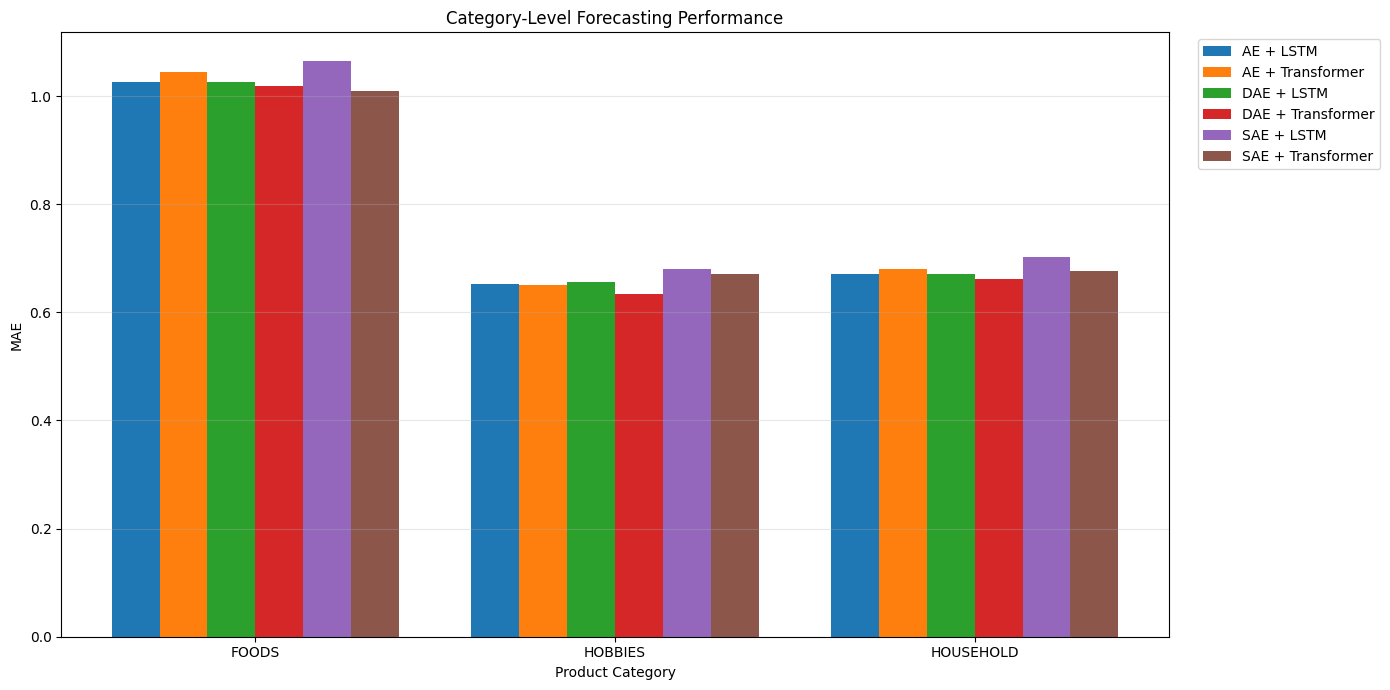

In [ ]:
plt.figure(
    figsize=(14, 7)
)

x = np.arange(
    len(
        category_mae_pivot.index
    )
)

models = list(
    category_mae_pivot.columns
)

width = (
    0.8 /
    max(
        len(models),
        1
    )
)

for i, model in enumerate(
    models
):

    plt.bar(
        x + i * width,
        category_mae_pivot[
            model
        ].values,
        width=width,
        label=model
    )

plt.xlabel(
    "Product Category"
)

plt.ylabel(
    "MAE"
)

plt.title(
    "Category-Level Forecasting Performance"
)

plt.xticks(
    x + width * (
        len(models) - 1
    ) / 2,
    category_mae_pivot.index
)

plt.legend(
    bbox_to_anchor=(
        1.02,
        1
    ),
    loc="upper left"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

CATEGORY_FIG = os.path.join(
    FIGURES_DIR,
    "category_level_model_comparison.png"
)

plt.savefig(
    CATEGORY_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
department_results = grouped_metrics(
    analysis_predictions,
    [
        "Model",
        "dept_id"
    ]
)

department_results = (
    department_results
    .sort_values([
        "dept_id",
        "Model"
    ])
    .reset_index(drop=True)
)

DEPARTMENT_RESULTS_PATH = os.path.join(
    FINAL_RESULTS_DIR,
    "department_level_results.csv"
)

department_results.to_csv(
    DEPARTMENT_RESULTS_PATH,
    index=False
)

print(
    "Calculated and saved department level results to:",
    DEPARTMENT_RESULTS_PATH
)

display(department_results.round(4).head())

Calculated and saved department level results to: /content/drive/MyDrive/GC210_Retail_Forecasting/results/final_analysis/department_level_results.csv


,Model,dept_id,MAE,RMSE,WAPE,sMAPE,Observations
0,AE + LSTM,FOODS_1,0.7672,1.3026,75.4535,105.5314,476
1,AE + Transformer,FOODS_1,0.7561,1.3244,74.3564,116.2987,476
2,DAE + LSTM,FOODS_1,0.8257,1.4446,81.2033,131.8586,476
3,DAE + Transformer,FOODS_1,0.8071,1.4366,79.3758,121.8602,476
4,SAE + LSTM,FOODS_1,0.8935,1.5900,87.8757,144.6867,476


State-level evaluation

In [ ]:
state_results = grouped_metrics(
    analysis_predictions,
    [
        "Model",
        "state_id"
    ]
)

state_results = (
    state_results
    .sort_values([
        "state_id",
        "Model"
    ])
    .reset_index(drop=True)
)

display(
    state_results.round(4)
)

,Model,state_id,MAE,RMSE,WAPE,sMAPE,Observations
0,AE + LSTM,CA,1.0485,2.2739,65.6534,111.3624,3164
1,AE + Transformer,CA,1.0664,2.4261,66.7766,120.5048,3164
2,DAE + LSTM,CA,1.0577,2.2659,66.2271,124.4650,3164
3,DAE + Transformer,CA,1.0289,2.2190,64.4278,113.6278,3164
4,SAE + LSTM,CA,1.0752,2.2963,67.3232,129.5153,3164
5,SAE + Transformer,CA,1.0178,2.2471,63.7307,109.9484,3164
6,AE + LSTM,TX,0.6780,1.4118,72.1056,114.9267,2912
7,AE + Transformer,TX,0.6927,1.4668,73.6711,131.6380,2912
8,DAE + LSTM,TX,0.6755,1.4169,71.8410,125.4386,2912
9,DAE + Transformer,TX,0.6768,1.4499,71.9768,121.3451,2912


In [ ]:
STATE_RESULTS_PATH = os.path.join(
    FINAL_RESULTS_DIR,
    "state_level_results.csv"
)

state_results.to_csv(
    STATE_RESULTS_PATH,
    index=False
)

Forecast-horizon analysis

In [ ]:
horizon_results = grouped_metrics(
    analysis_predictions,
    [
        "Model",
        "forecast_day"
    ]
)

horizon_results = (
    horizon_results
    .sort_values([
        "Model",
        "forecast_day"
    ])
    .reset_index(drop=True)
)

display(
    horizon_results.head(20).round(4)
)

,Model,forecast_day,MAE,RMSE,WAPE,sMAPE,Observations
0,AE + LSTM,1,0.7397,1.5863,71.1245,72.3825,300
1,AE + LSTM,2,0.7667,1.3710,73.4826,163.6432,300
2,AE + LSTM,3,0.7855,1.6005,77.0062,75.2670,300
3,AE + LSTM,4,0.7837,1.7591,84.5733,158.2563,300
4,AE + LSTM,5,0.8304,1.5358,78.8348,76.8660,300
5,AE + LSTM,6,0.8923,2.4921,70.4416,74.7048,300
6,AE + LSTM,7,0.9969,2.1856,71.5469,158.2913,300
7,AE + LSTM,8,0.7705,1.5925,73.8458,158.8114,300
8,AE + LSTM,9,0.8383,1.7378,71.2402,75.5805,300
9,AE + LSTM,10,0.6746,1.1798,77.5386,68.3625,300


Forecast-horizon analysis

In [ ]:
horizon_results = grouped_metrics(
    analysis_predictions,
    [
        "Model",
        "forecast_day"
    ]
)

horizon_results = (
    horizon_results
    .sort_values([
        "Model",
        "forecast_day"
    ])
    .reset_index(drop=True)
)

display(
    horizon_results.head(20).round(4)
)

,Model,forecast_day,MAE,RMSE,WAPE,sMAPE,Observations
0,AE + LSTM,1,0.7397,1.5863,71.1245,72.3825,300
1,AE + LSTM,2,0.7667,1.3710,73.4826,163.6432,300
2,AE + LSTM,3,0.7855,1.6005,77.0062,75.2670,300
3,AE + LSTM,4,0.7837,1.7591,84.5733,158.2563,300
4,AE + LSTM,5,0.8304,1.5358,78.8348,76.8660,300
5,AE + LSTM,6,0.8923,2.4921,70.4416,74.7048,300
6,AE + LSTM,7,0.9969,2.1856,71.5469,158.2913,300
7,AE + LSTM,8,0.7705,1.5925,73.8458,158.8114,300
8,AE + LSTM,9,0.8383,1.7378,71.2402,75.5805,300
9,AE + LSTM,10,0.6746,1.1798,77.5386,68.3625,300


In [ ]:
HORIZON_RESULTS_PATH = os.path.join(
    FINAL_RESULTS_DIR,
    "forecast_horizon_results.csv"
)

horizon_results.to_csv(
    HORIZON_RESULTS_PATH,
    index=False
)

Horizon MAE matrix

Horizon MAE matrix

In [ ]:
horizon_mae_pivot = (
    horizon_results
    .pivot(
        index="forecast_day",
        columns="Model",
        values="MAE"
    )
)

display(
    horizon_mae_pivot.round(4)
)

Model,AE + LSTM,AE + Transformer,DAE + LSTM,DAE + Transformer,SAE + LSTM,SAE + Transformer
forecast_day,,,,,,
1,0.7397,0.7650,0.7309,0.7151,0.7664,0.7544
2,0.7667,0.7748,0.7612,0.7646,0.7880,0.7611
3,0.7855,0.7870,0.7399,0.7297,0.7882,0.8121
4,0.7837,0.7108,0.7893,0.7633,0.8248,0.7703
5,0.8304,0.8045,0.7819,0.7837,0.7791,0.8049
6,0.8923,0.9179,0.8864,0.8778,0.8824,0.8628
7,0.9969,1.0326,0.9942,1.0185,1.0038,0.9946
8,0.7705,0.7850,0.7674,0.7470,0.7941,0.7651
9,0.8383,0.8767,0.8403,0.8320,0.8562,0.8410


Plot 28-day horizon performance

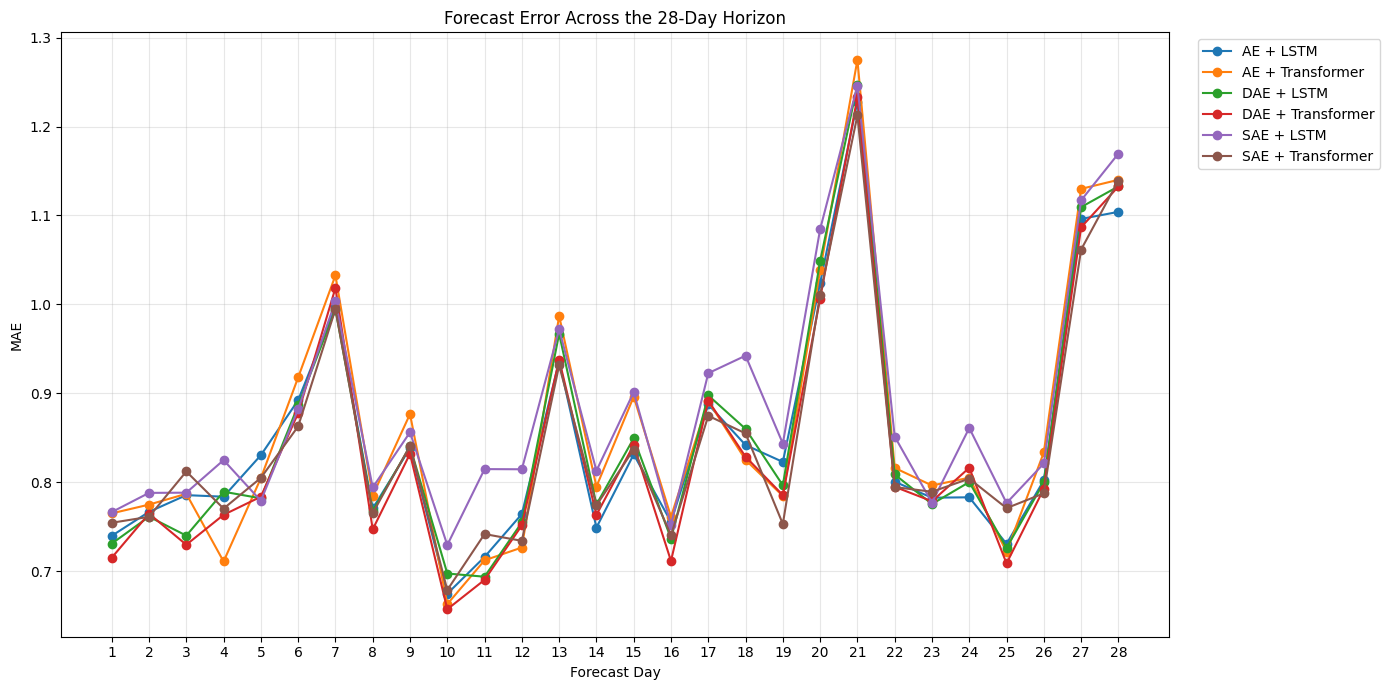

In [ ]:
plt.figure(
    figsize=(14, 7)
)

for model in (
    horizon_mae_pivot.columns
):

    plt.plot(
        horizon_mae_pivot.index,
        horizon_mae_pivot[
            model
        ],
        marker="o",
        label=model
    )

plt.xlabel(
    "Forecast Day"
)

plt.ylabel(
    "MAE"
)

plt.title(
    "Forecast Error Across the 28-Day Horizon"
)

plt.xticks(
    np.arange(
        1,
        29
    )
)

plt.legend(
    bbox_to_anchor=(
        1.02,
        1
    ),
    loc="upper left"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

HORIZON_FIG = os.path.join(
    FIGURES_DIR,
    "final_28day_horizon_comparison.png"
)

plt.savefig(
    HORIZON_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Short-, medium-, and long-horizon analysis

In [ ]:
def horizon_group(day):

    if day <= 7:
        return "Day 1-7"

    elif day <= 14:
        return "Day 8-14"

    else:
        return "Day 15-28"


analysis_predictions[
    "Horizon_Group"
] = (
    analysis_predictions[
        "forecast_day"
    ]
    .apply(
        horizon_group
    )
)

horizon_group_results = grouped_metrics(
    analysis_predictions,
    [
        "Model",
        "Horizon_Group"
    ]
)

display(
    horizon_group_results.round(4)
)

,Model,Horizon_Group,MAE,RMSE,WAPE,sMAPE,Observations
0,AE + LSTM,Day 1-7,0.8279,1.8283,74.8396,111.3444,2100
1,AE + LSTM,Day 15-28,0.8921,1.8523,71.0189,112.5553,4200
2,AE + LSTM,Day 8-14,0.7784,1.6142,69.0591,119.6361,2100
3,AE + Transformer,Day 1-7,0.8275,1.9252,74.8074,126.5832,2100
4,AE + Transformer,Day 15-28,0.9082,1.9434,72.2968,127.5334,4200
5,AE + Transformer,Day 8-14,0.7922,1.6943,70.2837,125.0999,2100
6,DAE + LSTM,Day 1-7,0.8120,1.8005,73.4039,82.6337,2100
7,DAE + LSTM,Day 15-28,0.8992,1.8631,71.5785,140.3566,4200
8,DAE + LSTM,Day 8-14,0.7851,1.6266,69.6523,137.9871,2100
9,DAE + Transformer,Day 1-7,0.8075,1.7962,73.0001,109.6294,2100


In [ ]:
HORIZON_GROUP_PATH = os.path.join(
    FINAL_RESULTS_DIR,
    "short_medium_long_horizon_results.csv"
)

horizon_group_results.to_csv(
    HORIZON_GROUP_PATH,
    index=False
)

Compare representation-learning families

In [ ]:
family_results = (
    latent_predictions[
        ["Model"]
    ]
    .drop_duplicates()
    .copy()
)

family_results[
    "Representation"
] = (
    family_results["Model"]
    .str.split(" + ")
    .str[0]
)

family_results[
    "Temporal_Model"
] = (
    family_results["Model"]
    .str.split(" + ")
    .str[1]
)

family_results = (
    family_results
    .merge(
        overall_metrics[
            [
                "Model",
                "MAE",
                "RMSE",
                "WAPE",
                "sMAPE"
            ]
        ],
        on="Model",
        how="left"
    )
)

display(
    family_results.round(4)
)

,Model,Representation,Temporal_Model,MAE,RMSE,WAPE,sMAPE
0,AE + LSTM,AE + LSTM,NaN,0.8476,1.7896,71.4440,114.0228
1,DAE + LSTM,DAE + LSTM,NaN,0.8488,1.7909,71.5465,125.3335
2,SAE + LSTM,SAE + LSTM,NaN,0.8819,1.8245,74.3301,132.4461
3,AE + Transformer,AE + Transformer,NaN,0.8590,1.8795,72.4039,126.6875
4,DAE + Transformer,DAE + Transformer,NaN,0.8372,1.7858,70.5612,119.5099
5,SAE + Transformer,SAE + Transformer,NaN,0.8449,1.7772,71.2111,115.7377


Representation × temporal-model MAE matrix

In [ ]:
representation_matrix = (
    family_results
    .pivot(
        index="Representation",
        columns="Temporal_Model",
        values="MAE"
    )
)

display(
    representation_matrix.round(4)
)

Temporal_Model,NaN
Representation,
AE + LSTM,0.8476
AE + Transformer,0.8590
DAE + LSTM,0.8488
DAE + Transformer,0.8372
SAE + LSTM,0.8819
SAE + Transformer,0.8449


In [ ]:
REPRESENTATION_MATRIX_PATH = os.path.join(
    FINAL_RESULTS_DIR,
    "representation_temporal_mae_matrix.csv"
)

representation_matrix.to_csv(
    REPRESENTATION_MATRIX_PATH
)

Compare AE/DAE/SAE + LSTM

In [ ]:
lstm_family = (
    family_results[
        family_results[
            "Temporal_Model"
        ] == "LSTM"
    ]
    .copy()
)

display(
    lstm_family[
        [
            "Representation",
            "MAE",
            "RMSE",
            "WAPE",
            "sMAPE"
        ]
    ].round(4)
)

,Representation,MAE,RMSE,WAPE,sMAPE


 Compare AE/DAE/SAE + Transformer
transformer_family = (

In [ ]:
transformer_family = (
    family_results[
        family_results[
            "Temporal_Model"
        ] == "Transformer"
    ]
    .copy()
)

display(
    transformer_family[
        [
            "Representation",
            "MAE",
            "RMSE",
            "WAPE",
            "sMAPE"
        ]
    ].round(4)
)

,Representation,MAE,RMSE,WAPE,sMAPE


Plot representation × temporal architecture

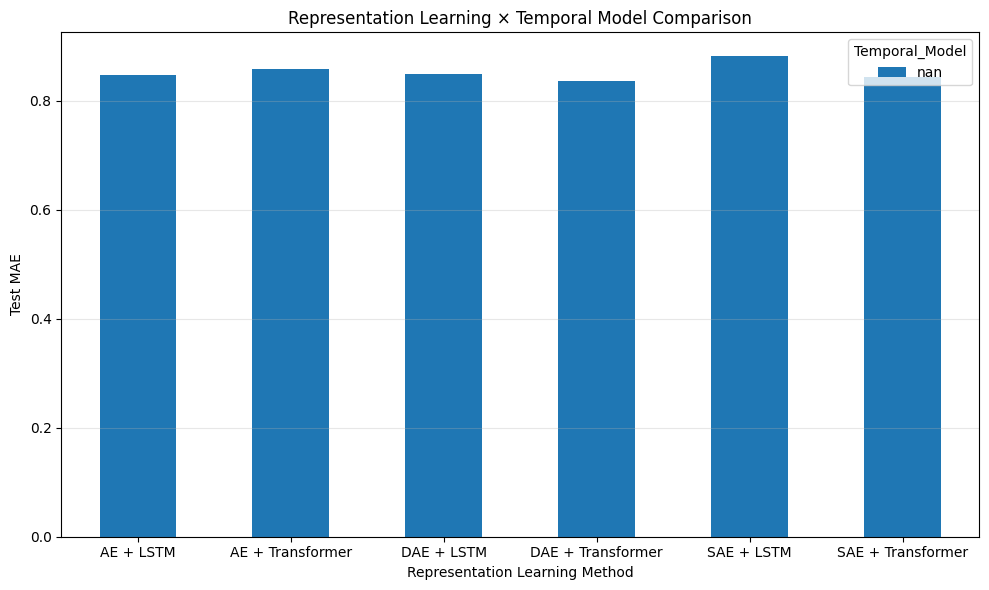

In [ ]:
representation_matrix.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.xlabel(
    "Representation Learning Method"
)

plt.ylabel(
    "Test MAE"
)

plt.title(
    "Representation Learning × Temporal Model Comparison"
)

plt.xticks(
    rotation=0
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

REPRESENTATION_FIG = os.path.join(
    FIGURES_DIR,
    "representation_temporal_comparison.png"
)

plt.savefig(
    REPRESENTATION_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Calculate improvement relative to direct MLP baseline

In [ ]:
mlp_rows = overall_metrics[
    overall_metrics[
        "Model"
    ] == "MLP"
]

if len(mlp_rows) > 0:

    mlp_mae = float(
        mlp_rows.iloc[0][
            "MAE"
        ]
    )

    improvement_df = (
        overall_metrics[
            [
                "Model",
                "MAE"
            ]
        ]
        .copy()
    )

    improvement_df[
        "MAE_Change_vs_MLP_Pct"
    ] = (
        (
            mlp_mae
            -
            improvement_df["MAE"]
        )
        /
        mlp_mae
    ) * 100

    display(
        improvement_df.round(4)
    )

else:

    print(
        "MLP baseline not available."
    )

,Model,MAE,MAE_Change_vs_MLP_Pct
0,Seasonal Naive,1.2555,-39.4434
1,MLP,0.9003,0.0000
2,LightGBM,0.8469,5.9381
3,AE + MLP,1.0662,-18.4177
4,DAE + MLP,1.1905,-32.2250
5,SAE + MLP,0.9248,-2.7162
6,LSTM,0.8332,7.4590
7,Transformer,0.8384,6.8810
8,AE + LSTM,0.8476,5.8551
9,DAE + LSTM,0.8488,5.7200


Compare hybrid models against direct sequence models

In [ ]:
comparison_rows = []

for direct_model in [
    "LSTM",
    "Transformer"
]:

    direct_row = overall_metrics[
        overall_metrics[
            "Model"
        ] == direct_model
    ]

    if len(direct_row) == 0:
        continue

    direct_mae = float(
        direct_row.iloc[0]["MAE"]
    )

    hybrid_models = [
        f"AE + {direct_model}",
        f"DAE + {direct_model}",
        f"SAE + {direct_model}"
    ]

    for hybrid_model in hybrid_models:

        hybrid_row = overall_metrics[
            overall_metrics[
                "Model"
            ] == hybrid_model
        ]

        if len(hybrid_row) == 0:
            continue

        hybrid_mae = float(
            hybrid_row.iloc[0]["MAE"]
        )

        change_pct = (
            (
                direct_mae
                -
                hybrid_mae
            )
            /
            direct_mae
        ) * 100

        comparison_rows.append({
            "Direct_Model":
                direct_model,

            "Hybrid_Model":
                hybrid_model,

            "Direct_MAE":
                direct_mae,

            "Hybrid_MAE":
                hybrid_mae,

            "MAE_Change_Pct":
                change_pct
        })


hybrid_improvement = pd.DataFrame(
    comparison_rows
)

display(
    hybrid_improvement.round(4)
)

,Direct_Model,Hybrid_Model,Direct_MAE,Hybrid_MAE,MAE_Change_Pct
0,LSTM,AE + LSTM,0.8332,0.8476,-1.7333
1,LSTM,DAE + LSTM,0.8332,0.8488,-1.8792
2,LSTM,SAE + LSTM,0.8332,0.8819,-5.8429
3,Transformer,AE + Transformer,0.8384,0.8590,-2.4600
4,Transformer,DAE + Transformer,0.8384,0.8372,0.1476
5,Transformer,SAE + Transformer,0.8384,0.8449,-0.7721


In [ ]:
HYBRID_IMPROVEMENT_PATH = os.path.join(
    FINAL_RESULTS_DIR,
    "hybrid_vs_direct_sequence_models.csv"
)

hybrid_improvement.to_csv(
    HYBRID_IMPROVEMENT_PATH,
    index=False
)

Statistical paired comparison preparation

In [ ]:
error_matrix = (
    analysis_predictions
    .pivot_table(
        index=[
            "series_key",
            "forecast_day"
        ],
        columns="Model",
        values="absolute_error",
        aggfunc="mean"
    )
)

print(
    "Matched error matrix:",
    error_matrix.shape
)

display(
    error_matrix.head()
)

Matched error matrix: (8400, 6)


Model                          AE + LSTM  AE + Transformer  DAE + LSTM  \
series_key       forecast_day                                            
FOODS_1_005_TX_3 1              0.019983          0.241348    0.974878   
                 2              1.097446          0.783013    0.010825   
                 3              2.816425          3.057863    3.985814   
                 4              0.436088          0.137740    0.970621   
                 5              0.434053          0.134690    0.979801   

Model                          DAE + Transformer  SAE + LSTM  \
series_key       forecast_day                                  
FOODS_1_005_TX_3 1                      0.322661    0.993279   
                 2                      0.680341    0.001892   
                 3                      3.304437    3.985355   
                 4                      0.197294    0.996574   
                 5                      0.149957    0.988187   

Model                          SAE + Transformer  
series_key       forecast_day                     
FOODS_1_005_TX_3 1                      0.013673  
                 2                      1.002342  
                 3                      2.998305  
                 4                      0.012075  
                 5                      0.002158

In [ ]:
ERROR_MATRIX_PATH = os.path.join(
    FINAL_RESULTS_DIR,
    "paired_absolute_error_matrix.csv"
)

error_matrix.to_csv(
    ERROR_MATRIX_PATH
)

Pairwise Wilcoxon signed-rank tests

In [ ]:
from scipy.stats import wilcoxon

model_names = list(
    error_matrix.columns
)

statistical_rows = []

for i in range(
    len(model_names)
):

    for j in range(
        i + 1,
        len(model_names)
    ):

        model_a = model_names[i]
        model_b = model_names[j]

        paired = (
            error_matrix[
                [model_a, model_b]
            ]
            .dropna()
        )

        if len(paired) == 0:
            continue

        differences = (
            paired[model_a]
            -
            paired[model_b]
        )

        if np.allclose(
            differences.values,
            0
        ):

            statistic = 0.0
            p_value = 1.0

        else:

            statistic, p_value = (
                wilcoxon(
                    paired[model_a],
                    paired[model_b]
                )
            )

        statistical_rows.append({

            "Model_A":
                model_a,

            "Model_B":
                model_b,

            "N":
                len(paired),

            "Wilcoxon_Statistic":
                statistic,

            "P_Value":
                p_value
        })


statistical_results = pd.DataFrame(
    statistical_rows
)

display(
    statistical_results.round(6)
)

,Model_A,Model_B,N,Wilcoxon_Statistic,P_Value
0,AE + LSTM,AE + Transformer,8400,12596363.5,0.003658
1,AE + LSTM,DAE + LSTM,8400,13053280.5,0.561123
2,AE + LSTM,DAE + Transformer,8400,11772110.5,0.000000
3,AE + LSTM,SAE + LSTM,8400,14218226.5,0.000314
4,AE + LSTM,SAE + Transformer,8400,14615351.0,0.037476
5,AE + Transformer,DAE + LSTM,8400,14404498.5,0.305938
6,AE + Transformer,DAE + Transformer,8400,12871443.5,0.000000
7,AE + Transformer,SAE + LSTM,8400,13976022.0,0.003105
8,AE + Transformer,SAE + Transformer,8400,15169568.0,0.036785
9,DAE + LSTM,DAE + Transformer,8400,10764634.5,0.000000


Multiple-comparison adjustment

In [ ]:
def holm_adjust(
    p_values
):

    p_values = np.asarray(
        p_values,
        dtype=float
    )

    n = len(p_values)

    order = np.argsort(
        p_values
    )

    sorted_p = p_values[
        order
    ]

    adjusted_sorted = np.empty(
        n,
        dtype=float
    )

    running_max = 0.0

    for i, p in enumerate(
        sorted_p
    ):

        adjusted = (
            (n - i) * p
        )

        running_max = max(
            running_max,
            adjusted
        )

        adjusted_sorted[i] = min(
            running_max,
            1.0
        )

    adjusted = np.empty(
        n,
        dtype=float
    )

    adjusted[
        order
    ] = adjusted_sorted

    return adjusted


if len(statistical_results) > 0:

    statistical_results[
        "Holm_Adjusted_P"
    ] = holm_adjust(
        statistical_results[
            "P_Value"
        ].values
    )

    statistical_results[
        "Significant_0.05"
    ] = (
        statistical_results[
            "Holm_Adjusted_P"
        ] < 0.05
    )

display(
    statistical_results.round(6)
)

,Model_A,Model_B,N,Wilcoxon_Statistic,P_Value,Holm_Adjusted_P,Significant_0.05
0,AE + LSTM,AE + Transformer,8400,12596363.5,0.003658,0.025608,True
1,AE + LSTM,DAE + LSTM,8400,13053280.5,0.561123,0.917814,False
2,AE + LSTM,DAE + Transformer,8400,11772110.5,0.000000,0.000000,True
3,AE + LSTM,SAE + LSTM,8400,14218226.5,0.000314,0.003140,True
4,AE + LSTM,SAE + Transformer,8400,14615351.0,0.037476,0.183925,False
5,AE + Transformer,DAE + LSTM,8400,14404498.5,0.305938,0.917814,False
6,AE + Transformer,DAE + Transformer,8400,12871443.5,0.000000,0.000000,True
7,AE + Transformer,SAE + LSTM,8400,13976022.0,0.003105,0.024836,True
8,AE + Transformer,SAE + Transformer,8400,15169568.0,0.036785,0.183925,False
9,DAE + LSTM,DAE + Transformer,8400,10764634.5,0.000000,0.000000,True


Important statistical interpretation

In [ ]:
interpretation_rows = []

for _, row in (
    statistical_results.iterrows()
):

    model_a = row["Model_A"]
    model_b = row["Model_B"]

    mean_a = (
        error_matrix[
            model_a
        ].mean()
    )

    mean_b = (
        error_matrix[
            model_b
        ].mean()
    )

    if mean_a < mean_b:

        lower_error_model = model_a

    elif mean_b < mean_a:

        lower_error_model = model_b

    else:

        lower_error_model = "Equal"

    interpretation_rows.append({

        "Model_A":
            model_a,

        "Model_B":
            model_b,

        "Mean_Absolute_Error_A":
            mean_a,

        "Mean_Absolute_Error_B":
            mean_b,

        "Lower_Observed_Error":
            lower_error_model,

        "Holm_Adjusted_P":
            row["Holm_Adjusted_P"],

        "Statistically_Significant_0.05":
            row["Significant_0.05"]
    })


statistical_interpretation = pd.DataFrame(
    interpretation_rows
)

display(
    statistical_interpretation.round(6)
)

,Model_A,Model_B,Mean_Absolute_Error_A,Mean_Absolute_Error_B,Lower_Observed_Error,Holm_Adjusted_P,Statistically_Significant_0.05
0,AE + LSTM,AE + Transformer,0.847632,0.859020,AE + LSTM,0.025608,True
1,AE + LSTM,DAE + LSTM,0.847632,0.848848,AE + LSTM,0.917814,False
2,AE + LSTM,DAE + Transformer,0.847632,0.837158,DAE + Transformer,0.000000,True
3,AE + LSTM,SAE + LSTM,0.847632,0.881873,AE + LSTM,0.003140,True
4,AE + LSTM,SAE + Transformer,0.847632,0.844869,SAE + Transformer,0.183925,False
5,AE + Transformer,DAE + LSTM,0.859020,0.848848,DAE + LSTM,0.917814,False
6,AE + Transformer,DAE + Transformer,0.859020,0.837158,DAE + Transformer,0.000000,True
7,AE + Transformer,SAE + LSTM,0.859020,0.881873,AE + Transformer,0.024836,True
8,AE + Transformer,SAE + Transformer,0.859020,0.844869,SAE + Transformer,0.183925,False
9,DAE + LSTM,DAE + Transformer,0.848848,0.837158,DAE + Transformer,0.000000,True


Create final results summary automatically

In [ ]:
# Save the statistical results first to satisfy the verification checklist
if 'statistical_results' in globals() and 'STATISTICAL_RESULTS_PATH' in globals():
    statistical_results.to_csv(STATISTICAL_RESULTS_PATH, index=False)
    print("Saved statistical results to:", STATISTICAL_RESULTS_PATH)

summary_rows = []

for _, row in ranked_metrics.iterrows():

    summary_rows.append({

        "Model":
            row["Model"],

        "MAE":
            row["MAE"],

        "RMSE":
            row["RMSE"],

        "WAPE":
            row["WAPE"],

        "sMAPE":
            row["sMAPE"]
    })

final_summary = pd.DataFrame(
    summary_rows
)

display(
    final_summary.round(4)
)

Saved statistical results to: /content/drive/MyDrive/GC210_Retail_Forecasting/results/final_analysis/statistical_tests_results.csv


,Model,MAE,RMSE,WAPE,sMAPE
0,LSTM,0.8332,1.7894,70.2268,127.8854
1,DAE + Transformer,0.8372,1.7858,70.5612,119.5099
2,Transformer,0.8384,1.7694,70.6655,133.3020
3,SAE + Transformer,0.8449,1.7772,71.2111,115.7377
4,LightGBM,0.8469,1.8054,71.3810,102.4982
5,AE + LSTM,0.8476,1.7896,71.4440,114.0228
6,DAE + LSTM,0.8488,1.7909,71.5465,125.3335
7,AE + Transformer,0.8590,1.8795,72.4039,126.6875
8,SAE + LSTM,0.8819,1.8245,74.3301,132.4461
9,MLP,0.9003,1.8435,75.8873,151.5955


In [ ]:
FINAL_SUMMARY_PATH = os.path.join(
    FINAL_RESULTS_DIR,
    "final_results_summary.csv"
)

final_summary.to_csv(
    FINAL_SUMMARY_PATH,
    index=False
)

Print lowest observed error for each metric

In [ ]:
print("=" * 70)
print("LOWEST OBSERVED TEST ERROR BY METRIC")
print("=" * 70)

for metric in [
    "MAE",
    "RMSE",
    "WAPE",
    "sMAPE"
]:

    valid = overall_metrics[
        [
            "Model",
            metric
        ]
    ].dropna()

    if len(valid) == 0:
        continue

    idx = valid[
        metric
    ].idxmin()

    model_name = (
        overall_metrics.loc[
            idx,
            "Model"
        ]
    )

    value = (
        overall_metrics.loc[
            idx,
            metric
        ]
    )

    print(
        f"{metric:8s}: "
        f"{model_name:25s} "
        f"{value:.4f}"
    )

LOWEST OBSERVED TEST ERROR BY METRIC
MAE     : LSTM                      0.8332
RMSE    : Transformer               1.7694
WAPE    : LSTM                      70.2268
sMAPE   : Seasonal Naive            86.5290


Final verification

In [ ]:
print("=" * 88)
print("STEP 13 - FINAL MODEL EVALUATION AND MULTI-LEVEL ANALYSIS")
print("=" * 88)

print("\n1. OVERALL EVALUATION")
print("-" * 55)

print(
    "Models evaluated:",
    overall_metrics[
        "Model"
    ].nunique()
)

print(
    "Metrics:",
    ", ".join(
        METRIC_COLUMNS
    )
)


print("\n2. MULTI-LEVEL ANALYSIS")
print("-" * 55)

print(
    "Stores:",
    analysis_predictions[
        "store_id"
    ].nunique()
)

print(
    "Categories:",
    analysis_predictions[
        "cat_id"
    ].nunique()
)

print(
    "Departments:",
    analysis_predictions[
        "dept_id"
    ].nunique()
)

print(
    "States:",
    analysis_predictions[
        "state_id"
    ].nunique()
)

print(
    "Series:",
    analysis_predictions[
        "series_key"
    ].nunique()
)

print(
    "Forecast horizon:",
    analysis_predictions[
        "forecast_day"
    ].nunique()
)


print("\n3. REPRESENTATION + TEMPORAL EXPERIMENTS")
print("-" * 55)

for model in (
    latent_predictions[
        "Model"
    ].unique()
):
    print(model)


print("\n4. OUTPUT FILES")
print("-" * 55)

# Define the missing path variables
SERIES_RESULTS_PATH = os.path.join(FINAL_RESULTS_DIR, "series_level_results.csv")
SERIES_SUMMARY_PATH = os.path.join(FINAL_RESULTS_DIR, "series_level_summary.csv")
STATISTICAL_RESULTS_PATH = os.path.join(FINAL_RESULTS_DIR, "statistical_tests_results.csv")

files_to_check = {

    "Overall results":
        OVERALL_RESULTS_PATH,

    "Store results":
        STORE_RESULTS_PATH,

    "Category results":
        CATEGORY_RESULTS_PATH,

    "Department results":
        DEPARTMENT_RESULTS_PATH,

    "State results":
        STATE_RESULTS_PATH,

    "Horizon results":
        HORIZON_RESULTS_PATH,

    "Horizon groups":
        HORIZON_GROUP_PATH,

    "Representation matrix":
        REPRESENTATION_MATRIX_PATH,

    "Hybrid comparison":
        HYBRID_IMPROVEMENT_PATH,

    "Paired errors":
        ERROR_MATRIX_PATH,

    "Statistical tests":
        STATISTICAL_RESULTS_PATH,

    "Final summary":
        FINAL_SUMMARY_PATH
}

all_saved = True

for name, path in (
    files_to_check.items()
):

    exists = os.path.exists(
        path
    )

    print(
        f"{name:30s}:",
        "FOUND"
        if exists
        else "MISSING"
    )

    if not exists:
        all_saved = False


print("\n" + "=" * 88)

if all_saved:

    print(
        "STEP 13 COMPLETED SUCCESSFULLY"
    )

    print(
        "OVERALL + STORE + CATEGORY + "
        "DEPARTMENT + STATE + HORIZON + "
        "STATISTICAL ANALYSIS COMPLETED"
    )

else:

    print(
        "STEP 13 INCOMPLETE - "
        "CHECK MISSING FILES ABOVE"
    )

print("=" * 88)

STEP 13 - FINAL MODEL EVALUATION AND MULTI-LEVEL ANALYSIS

1. OVERALL EVALUATION
-------------------------------------------------------
Models evaluated: 14
Metrics: MAE, RMSE, WAPE, sMAPE

2. MULTI-LEVEL ANALYSIS
-------------------------------------------------------
Stores: 10
Categories: 3
Departments: 7
States: 3
Series: 300
Forecast horizon: 28

3. REPRESENTATION + TEMPORAL EXPERIMENTS
-------------------------------------------------------
AE + LSTM
DAE + LSTM
SAE + LSTM
AE + Transformer
DAE + Transformer
SAE + Transformer

4. OUTPUT FILES
-------------------------------------------------------
Overall results               : FOUND
Store results                 : FOUND
Category results              : FOUND
Department results            : FOUND
State results                 : FOUND
Horizon results               : FOUND
Horizon groups                : FOUND
Representation matrix         : FOUND
Hybrid comparison             : FOUND
Paired errors                 : FOUND
Statistica